<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockDT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Rows: 332 | Train: 215 | Validation: 50 | Test: 67
Class counts (train): {0: 123, 1: 92}
Class counts (validation): {0: 29, 1: 21}
Class counts (test): {0: 39, 1: 28}
Automatic class weights: {0: np.float64(0.8739837398373984), 1: np.float64(1.1684782608695652)}
Selected parameters: {'ccp_alpha': 0.0, 'class_weight': {0: np.float64(0.8739837398373984), 1: np.float64(1.1684782608695652)}, 'criterion': 'gini', 'max_depth': 2, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}

TEST METRICS
 Accuracy             0.641791
Balanced_Accuracy    0.611722
Precision            0.600000
Recall               0.428571
F1                   0.500000
ROC_AUC              0.633700
PR_AUC               0.581663
Threshold            0.500000
dtype: float64

Confusion matrix:
 [[31  8]
 [16 12]]

Classification re

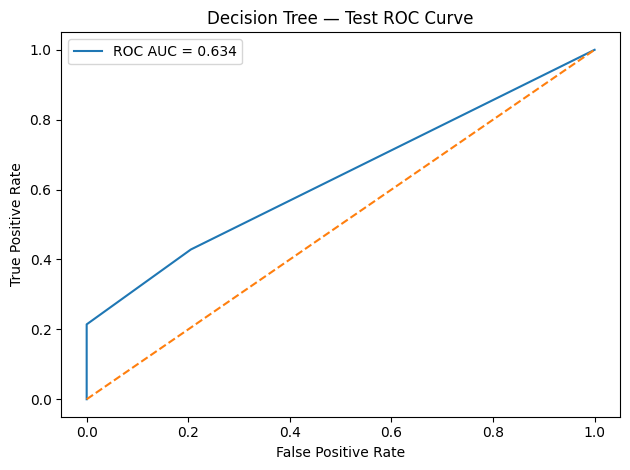

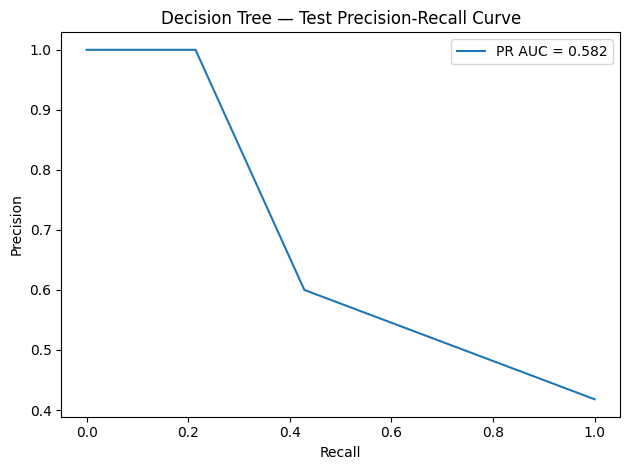

Saved results to: /content/drive/MyDrive/DT_results


In [2]:

# ============================================================
# DECISION TREE — HANCOCK HPV CLASSIFIER
# Shared data preparation | Seed 42 | No SMOTE
# ============================================================

import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
drive.mount("/content/drive")

# ------------------------------------------------------------
# 1. LOAD AND PREPARE DATA
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "DT_results")
os.makedirs(OUT_DIR, exist_ok=True)

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)
    raise ValueError(f"Cannot read table from {path}")

clinical = load_json_table(os.path.join(BASE, "clinical_data.json"))
pathology = load_json_table(os.path.join(BASE, "pathological_data.json"))
if "patient_id" not in clinical or "patient_id" not in pathology:
    raise KeyError("Both files must contain patient_id.")

df = clinical.merge(pathology, on="patient_id", how="left", suffixes=("", "_path"))
target_candidates = ["hpv_association_p16", "hpv_association_p16_path"]
target_col = next((c for c in target_candidates if c in df.columns), None)
if target_col is None:
    raise KeyError("HPV target column was not found.")

feature_candidates = {
    "age_at_initial_diagnosis": ["age_at_initial_diagnosis"],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": ["pN_stage", "pN_stage_path", "pathological_N_stage",
                 "pathologic_N_stage", "pathological_n_stage"]
}
rename_map = {}
for name, candidates in feature_candidates.items():
    match = next((c for c in candidates if c in df.columns), None)
    if match is None:
        raise KeyError(f"Missing predictor {name}; checked {candidates}")
    if match != name:
        rename_map[match] = name
df = df.rename(columns=rename_map)
features = list(feature_candidates.keys())

def normalize_label(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if value in {"negative", "neg", "0", "false", "no"}:
        return 0
    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1
    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[["patient_id"] + features + ["HPV_Label"]].copy()

train_val, test = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train, val = train_test_split(
    train_val, test_size=0.1875, random_state=SEED,
    stratify=train_val["HPV_Label"]
)

print("Rows:", len(df), "| Train:", len(train), "| Validation:", len(val), "| Test:", len(test))
print("Class counts (train):", train["HPV_Label"].value_counts().sort_index().to_dict())
print("Class counts (validation):", val["HPV_Label"].value_counts().sort_index().to_dict())
print("Class counts (test):", test["HPV_Label"].value_counts().sort_index().to_dict())

numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [c for c in features if c not in numeric_features]
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]),
     numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder)
    ]), categorical_features)
])

X_train = preprocessor.fit_transform(train[features])
X_val = preprocessor.transform(val[features])
X_test = preprocessor.transform(test[features])
y_train = train["HPV_Label"].to_numpy()
y_val = val["HPV_Label"].to_numpy()
y_test = test["HPV_Label"].to_numpy()

counts = np.bincount(y_train, minlength=2)
class_weights = {i: len(y_train) / (2 * counts[i]) for i in range(2)}
print("Automatic class weights:", class_weights)

# ------------------------------------------------------------
# 2. SELECT TREE SETTINGS USING VALIDATION DATA ONLY
# ------------------------------------------------------------

grid = {
    "max_depth": [2, 3, 4, 5, 7, None],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

best_model = None
best_threshold = 0.5
best_key = None
tuning_rows = []

for params in ParameterGrid(grid):
    candidate = DecisionTreeClassifier(
        **params, class_weight=class_weights, random_state=SEED
    )
    candidate.fit(X_train, y_train)
    val_prob = candidate.predict_proba(X_val)[:, 1]
    thresholds = np.linspace(0.10, 0.90, 81)
    scores = [
        balanced_accuracy_score(y_val, (val_prob >= t).astype(int))
        for t in thresholds
    ]
    max_score = max(scores)
    threshold = min(
        (t for t, score in zip(thresholds, scores) if score == max_score),
        key=lambda t: abs(t - 0.5)
    )
    val_pred = (val_prob >= threshold).astype(int)
    auc = roc_auc_score(y_val, val_prob) if len(np.unique(y_val)) == 2 else 0.5
    pr_auc = average_precision_score(y_val, val_prob)
    key = (max_score, auc, pr_auc)
    tuning_rows.append({
        **params,
        "validation_balanced_accuracy": max_score,
        "validation_roc_auc": auc,
        "validation_pr_auc": pr_auc,
        "threshold": float(threshold)
    })
    if best_key is None or key > best_key:
        best_key = key
        best_model = candidate
        best_threshold = float(threshold)

pd.DataFrame(tuning_rows).sort_values(
    ["validation_balanced_accuracy", "validation_roc_auc", "validation_pr_auc"],
    ascending=False
).to_csv(os.path.join(OUT_DIR, "validation_tuning.csv"), index=False)

# ------------------------------------------------------------
# 3. FINAL TEST EVALUATION AND SAVE OUTPUTS
# ------------------------------------------------------------

test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Balanced_Accuracy": balanced_accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, test_prob) if len(np.unique(y_test)) == 2 else np.nan,
    "PR_AUC": average_precision_score(y_test, test_prob),
    "Threshold": best_threshold
}
print("Selected parameters:", best_model.get_params())
print("\nTEST METRICS\n", pd.Series(metrics))
print("\nConfusion matrix:\n", confusion_matrix(y_test, test_pred))
print("\nClassification report:\n",
      classification_report(y_test, test_pred, zero_division=0))

pd.DataFrame([metrics]).to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
pd.DataFrame({
    "patient_id": test["patient_id"].to_numpy(),
    "y_true": y_test, "probability_positive": test_prob,
    "prediction": test_pred
}).to_csv(os.path.join(OUT_DIR, "test_predictions.csv"), index=False)

try:
    feature_names = preprocessor.get_feature_names_out()
    importance = pd.DataFrame({
        "feature": feature_names,
        "importance": best_model.feature_importances_
    }).sort_values("importance", ascending=False)
    importance.to_csv(os.path.join(OUT_DIR, "feature_importance.csv"), index=False)
except Exception as e:
    print("Could not export feature names:", e)

with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump({
        "model": "Decision Tree", "seed": SEED,
        "features": features, "target_column": target_col,
        "best_parameters": best_model.get_params(),
        "threshold": best_threshold, "class_weight": class_weights,
        "smote": False,
        "split": {"train": len(train), "validation": len(val), "test": len(test)}
    }, f, indent=2, default=str)

if len(np.unique(y_test)) == 2:
    fpr, tpr, _ = roc_curve(y_test, test_prob)
    plt.figure()
    plt.plot(fpr, tpr, label=f"ROC AUC = {metrics['ROC_AUC']:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Decision Tree — Test ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "roc_curve.png"), dpi=150)
    plt.show()

    precision, recall, _ = precision_recall_curve(y_test, test_prob)
    plt.figure()
    plt.plot(recall, precision, label=f"PR AUC = {metrics['PR_AUC']:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Decision Tree — Test Precision-Recall Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "pr_curve.png"), dpi=150)
    plt.show()

print("Saved results to:", OUT_DIR)
